<a href="https://colab.research.google.com/github/SofiaSchweitzer/ml4amplitudes/blob/main/classifier_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Training a binary classifier for amplitudes

We want to study whether we can use a binary classifier to predict whether a scrambled amplitude reduces to zero or not. In this setup, we treat reducing to zero as "signal" or class 1, and not reducing to zero as "background" or class 0.

#### Relevant papers
Learning the Simplicity of Scattering Amplitudes, <br> *Clifford Cheung, Aurélien Dersy, Matthew D. Schwartz* ,<br> https://arxiv.org/pdf/2408.04720

Learning to Unscramble:
Simplifying Symbolic Expressions via Self-Supervised Oracle Trajectories, <br> *David Shih*,<br>https://arxiv.org/pdf/2603.11164




Let's import relevant libraries

In [ ]:
import torch
import torch.nn as nn
import time
import itertools
import re
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(device)

cuda


We will start by loading scrambled amplitudes from ...

In [ ]:
!wget -q -O data.zip "https://www.dropbox.com/scl/fo/hvrw0aeegxfwv3tvp20vu/ACz4KyuXR_D2Qw1QKsRsUr4/v2?dl=1&rlkey=snk2lmoxt61hj0dli7y4mgjqw&subfolder_nav_tracking"
!unzip -o -q data.zip -d data 2>/dev/null; ls data

background.pkl	signal.pkl


In [ ]:
bkg = np.load("data/background.pkl", allow_pickle=True)
sig = np.load("data/signal.pkl", allow_pickle=True)

### Exercise 1 - Study the data

Get familiar with the dataset. Do this by looking at the format and the structure of the expressions. What would you feed into the classifier?

In [ ]:
for key in bkg.keys():
    print(key)

expression
recipe
mutation
scrambles_a
scrambles_x
numerator_terms
base_expression
other_expression
info


In [ ]:
bkg["expression"][0]

'(3*ab(1, 2)*ab(2, 3)*ab(3, 4)*sb(1, 2)*sb(1, 4)*sb(3, 4)**2 - 5*ab(1, 2)*ab(2, 3)*ab(3, 4)*sb(1, 3)*sb(1, 4)*sb(2, 4)*sb(3, 4) + 3*ab(1, 2)*ab(2, 3)*ab(3, 4)*sb(1, 4)**2*sb(2, 3)*sb(3, 4) - 4*ab(1, 2)*ab(2, 4)**2*sb(1, 4)**2*sb(2, 4)**2 + 3*ab(1, 4)*ab(2, 3)**2*sb(1, 2)*sb(1, 4)*sb(3, 4)**2 - 5*ab(1, 4)*ab(2, 3)**2*sb(1, 3)*sb(1, 4)*sb(2, 4)*sb(3, 4) + 3*ab(1, 4)*ab(2, 3)**2*sb(1, 4)**2*sb(2, 3)*sb(3, 4))/(ab(2, 3)*ab(2, 4)*sb(1, 2))'

Every expression is stored as `(numerator)/(denominator)`, where the denominator is a single product of brackets. The expression is zero exactly when the numerator is zero, so we only encode the numerator.
The numerator is a sum of terms, and each term is an integer coefficient times a product of brackets. With 4 particles there are only 12 possible brackets.

Now, a key ingredient to symbolic ML is to find a representation that is understandable for a classifier.

In our case, we can describe each term with 14 coefficients:
- `log(1 + |coefficient|)` and the sign of the coefficient
- the power of each of the 12 brackets (0 if the bracket is absent)

An expression has at most 10 numerator terms in this dataset.As we will start with a simple MLP, the input needs to be ordered and flattened. Therefore, we stack the terms into a 10 × 14 table, sort the rows so the order is always the same, fill unused rows with zeros, and flatten. Each expression becomes a vector of 140 numbers.

In [ ]:
class TransformData:
    def __init__(self, n_point=4, max_terms=20):
        """
        Initializes the transformation from expression strings to feature vectors.

        Args:
            n_point (int): Number of external particles.
            max_terms (int): Maximum number of numerator terms, shorter expressions are zero-padded.
        """
        self.n_point = n_point
        self.max_terms = max_terms

        # All brackets ab(i, j) and sb(i, j) with i < j, one column each
        self.pairs = [(i, j) for i in range(1, n_point + 1) for j in range(i + 1, n_point + 1)]
        self.columns = [f"{t}{i}{j}" for t in ("ab", "sb") for i, j in self.pairs]
        self.col_index = {name: k for k, name in enumerate(self.columns)}

        # Coefficient (log magnitude and sign) plus one power per bracket
        self.term_dim = 2 + len(self.columns)
        self.dims_in = self.max_terms * self.term_dim

        self.bracket = re.compile(r"(ab|sb)\((\d), (\d)\)(?:\*\*(\d+))?")
        self.coeff = re.compile(r"^(-?)(\d+)?\*?")

    def split_numerator(self, expr):
        """
        Splits off the numerator of an expression.

        Args:
            expr (str): Expression of the form "(num)/(den)" or a polynomial without denominator.

        Returns:
            str: Numerator without outer brackets.
            bool: True if the numerator has an overall minus sign.
        """
        depth = 0
        for k, ch in enumerate(expr):
            depth += (ch == "(") - (ch == ")")
            if ch == "/" and depth == 0:
                num = expr[:k]
                break
        else:
            num = expr

        neg = num.startswith("-(")
        if neg:
            num = num[1:]
        if num.startswith("(") and num.endswith(")"):
            num = num[1:-1]
        return num, neg

    def encode_term(self, term, flip):
        """
        Encodes a single term as coefficient and bracket powers.

        Args:
            term (str): Term like "2*ab(1, 2)*sb(2, 3)**2".
            flip (bool): If True, flips the sign of the term.

        Returns:
            ndarray: Feature vector of size `self.term_dim`.
        """
        row = np.zeros(self.term_dim, dtype=np.float32)

        sign, digits = self.coeff.match(term).groups()
        c = int(digits) if digits else 1
        row[0] = np.log1p(c)
        row[1] = -1.0 if (sign == "-") != flip else 1.0

        for kind, i, j, p in self.bracket.findall(term):
            i, j = sorted((int(i), int(j)))
            row[2 + self.col_index[f"{kind}{i}{j}"]] += int(p) if p else 1
        return row

    def encode(self, expr):
        """
        Encodes an expression as a flat vector of its numerator terms.

        Args:
            expr (str): Expression string.

        Returns:
            ndarray: Feature vector of size `self.dims_in`.
        """
        num, flip = self.split_numerator(expr)
        terms = num.replace(" - ", " + -").split(" + ")

        # Sort the terms so that the input does not depend on their order
        rows = sorted((self.encode_term(t, flip) for t in terms), key=lambda r: r.tobytes())

        x = np.zeros((self.max_terms, self.term_dim), dtype=np.float32)
        x[:len(rows)] = rows[:self.max_terms]
        return x.ravel()

    def __call__(self, expressions):
        """
        Encodes a list of expressions.

        Args:
            expressions (list): Expression strings.

        Returns:
            Tensor: Features of shape (len(expressions), `self.dims_in`).
        """
        return torch.tensor(np.stack([self.encode(e) for e in expressions]))


Let's look at how this changes the expression

In [ ]:
transform = TransformData()

print("coeff, sign,", ", ".join(transform.columns))
print(transform.encode(bkg["expression"][0]).reshape(transform.max_terms, transform.term_dim)[:4])

coeff, sign, ab12, ab13, ab14, ab23, ab24, ab34, sb12, sb13, sb14, sb23, sb24, sb34
[[ 1.609438  -1.         1.         0.         0.         0.
   2.         0.         0.         0.         2.         0.
   2.         0.       ]
 [ 1.3862944  1.         0.         0.         1.         2.
   0.         0.         0.         0.         2.         1.
   0.         1.       ]
 [ 1.3862944  1.         0.         0.         1.         2.
   0.         0.         1.         0.         1.         0.
   0.         2.       ]
 [ 1.3862944  1.         1.         0.         0.         1.
   0.         1.         0.         0.         2.         1.
   0.         1.       ]]


We now apply the transformation to our datasets

In [ ]:
t0 = time.time()

sig_data = transform(sig["expression"])
bkg_data = transform(bkg["expression"])
print(f"Signal {tuple(sig_data.shape)}, background {tuple(bkg_data.shape)}, encoded in {round(time.time() - t0, 1)}s")

Signal (255664, 280), background (244336, 280), encoded in 84.2s


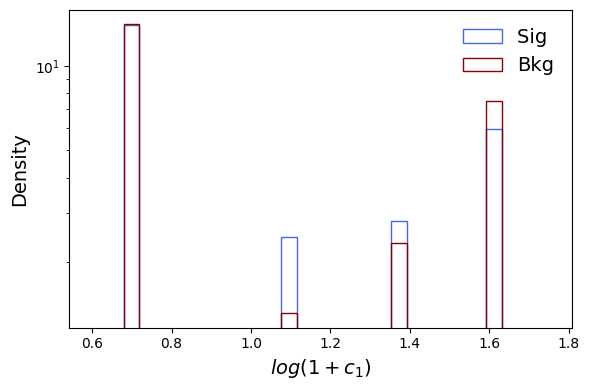

In [ ]:
# Plot
plt.figure(figsize=(6, 4))
plt.hist(sig_data[:,0], bins=np.linspace(0.6,1.75,30), label="Sig ", density=True, color="royalblue", histtype="step")
plt.hist(bkg_data[:, 0], bins=np.linspace(0.6,1.75,30), label="Bkg", density=True, color="darkred", histtype="step")


plt.xlabel(r"$log (1 + c_1)$",
          fontsize=14)

plt.ylabel("Density",
        fontsize=14)

plt.yscale("log")
plt.legend(frameon=False, fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
def num_terms(x, term_dim):
  """
  Counts the real (non-padded) terms of encoded expressions.

  Args:
      x (Tensor): Encoded expressions, shape (N, max_terms * term_dim) or (N, max_terms, term_dim).
      term_dim (int): Number of features per term.

  Returns:
      Tensor: Number of terms per expression, shape (N,).
  """
  x = x.reshape(len(x), -1, term_dim)
  return (x.abs().sum(-1) > 0).sum(-1)

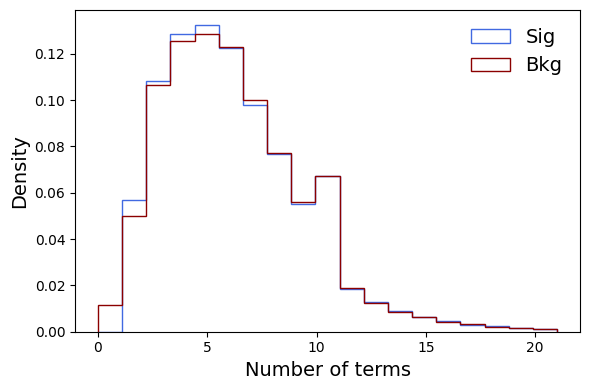

In [ ]:
plt.figure(figsize=(6, 4))

plt.hist(num_terms(sig_data, transform.term_dim), bins=np.linspace(0,21, 20), color="royalblue", histtype="step", label="Sig", density=True)
plt.hist(num_terms(bkg_data, transform.term_dim), bins=np.linspace(0,21, 20), color="darkred", histtype="step", label="Bkg", density=True)

plt.xlabel(r"Number of terms",
          fontsize=14)

plt.ylabel("Density",
        fontsize=14)


plt.legend(frameon=False, fontsize=14)
plt.tight_layout()
plt.show()

Lastly, we separate our datasets into test and train

In [ ]:
sig_data = sig_data.to(device)
bkg_data = bkg_data.to(device)

sig_data_train, sig_data_test = sig_data[:150000], sig_data[150000:]
bkg_data_train, bkg_data_test = bkg_data[:150000], bkg_data[150000:]

### Exercise 2 – Building a Classifier in PyTorch

In this first exercise, we will implement a binary classifier using PyTorch.

The aim is to build a reusable classifier class. This modular design allows us to train and evaluate the classifier multiple times throughout our tutorial.

#### Structure of the Classifier

Your classifier should be implemented as a Python class with the following components:

1. **Initialization (`__init__`)**  
   Here, we define:
   - `dims_in`: the number of input features,
   - `params`: a dictionary of hyperparameters (such as learning rate, network size, and number of training epochs).

2. **Building Network (`init_network`)**  
   Define a fully connected feedforward neural network with:
   - One input layer,
   - A configurable number of hidden layers using ReLU activations,
   - A final output layer with a single unit producing logits.

3. **Loss Function (`batch_loss`)**  
   Implement a method that computes the binary cross-entropy loss for a given batch of:
   - input features `x`,
   - labels `y`

4. **Training Loop (`train_classifier`)**  
   Create a training loop that:
   - Accepts signal (`sig_data`) and background(`bkg_data`) samples,
   - Trains the classifier using the Adam optimizer and a learning rate scheduler.

5. **Evaluation (`evaluate`)**  
   Evaluate the classifier on new data and return either:
   - `exp(logit)`, which gives the likelihood ratio,
   - or `sigmoid(logit)`, which gives the predicted signal probability.


In [ ]:
class Classifier(nn.Module):
    def __init__(self, dims_in, params):
        """
        Initializes the classifier model.

        Args:
            dims_in (int): Dimensionality of input features.
            params (dict): Dictionary of model and training hyperparameters.
        """
        super().__init__()
        self.dims_in = dims_in
        self.params = params
        self.init_network()

    def init_network(self):
        """
        Initializes a fully connected feedforward neural network.
        """
        # TODO:
        #    - Build a network to predict the class.
        #    - Use 3 hidden layers of size `self.params["embedding_dim"]`
        #    - Add non-linear activation functions and dropouts with `self.params["dropout"]`
        #    - The last layer need to map back to the class dimension

        self.net = nn.Sequential(
            nn.Linear(self.dims_in, self.params["embedding_dim"]),
            nn.ReLU(),
            nn.Dropout(self.params["dropout"]),
            nn.Linear(self.params["embedding_dim"], self.params["embedding_dim"]),
            nn.ReLU(),
            nn.Dropout(self.params["dropout"]),
            nn.Linear(self.params["embedding_dim"], self.params["embedding_dim"]),
            nn.ReLU(),
            nn.Dropout(self.params["dropout"]),
            nn.Linear(self.params["embedding_dim"], 1)
        )

    def batch_loss(self, x, y):
        """
        Computes the BCE loss for a batch.

        Args:
            x (Tensor): Input features.
            y (Tensor): Labels (0 or 1).

        Returns:
            Tensor: Scalar loss value.
        """
        # TODO: Implement the batch_loss function
        # Hint: You can use either torch.nn.BCEWithLogitsLoss or
        # torch.nn.BCE. What's the difference?

        pred = self.net(x).squeeze()
        loss = torch.nn.BCEWithLogitsLoss()(pred, y)
        return loss

    def train_classifier(self,
                         sig_data,
                         bkg_data):
        """
        Trains the classifier on provided signal (y=1) and background (y=0) data.

        Args:
            sig_data (Tensor): Data with label 1.
            bkg_data (Tensor): Data with label 0.
        """

        device = sig_data.device
        dtype = sig_data.dtype

        loader_sig_train = torch.utils.data.DataLoader(
            sig_data[:-10000],
            batch_size=self.params["batch_size"], shuffle=True,
            )

        loader_bkg_train = torch.utils.data.DataLoader(
            bkg_data[:-10000],
            batch_size=self.params["batch_size"], shuffle=True,
            )

        loader_sig_val = torch.utils.data.DataLoader(
            sig_data[-10000:],
            batch_size=self.params["batch_size"], shuffle=True,
            )

        loader_bkg_val = torch.utils.data.DataLoader(
            bkg_data[-10000:],
            batch_size=self.params["batch_size"], shuffle=True,
            )

        optimizer = torch.optim.Adam(self.net.parameters(), lr=self.params["lr"])
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer=optimizer,
            max_lr=self.params.get("max_lr", 3 * self.params["lr"]),
            epochs=self.params["n_epochs"],
            steps_per_epoch=min(len(loader_sig_train), len(loader_bkg_train)))

        print(f"Training classifier for {self.params['n_epochs']} epochs with lr {self.params['lr']}")
        t0 = time.time()

        for epoch in range(self.params["n_epochs"]):
            losses = []
            val_losses = []
            for x_sig, x_bkg in zip(loader_sig_train, loader_bkg_train):
                self.net.train()
                label_sig = torch.ones((x_sig.shape[0]), device=device, dtype=dtype)
                label_bkg = torch.zeros((x_bkg.shape[0]), device=device, dtype=dtype)
                # TODO: Write training loop

                # Reset optimizer
                optimizer.zero_grad()

                # Calculate batch loss once for sig and bkg
                loss = self.batch_loss(x_sig, label_sig)
                loss += self.batch_loss(x_bkg, label_bkg)

                # Backpropagate
                loss.backward()

                # Update optimizer and scheduler
                optimizer.step()
                scheduler.step()

                losses.append(loss.item())

            for x_sig, x_bkg in zip(loader_sig_val, loader_bkg_val):
                label_sig = torch.ones((x_sig.shape[0]), device=device, dtype=dtype)
                label_bkg = torch.zeros((x_bkg.shape[0]), device=device, dtype=dtype)
                self.net.eval()
                with torch.no_grad():
                    val_loss = self.batch_loss(x_sig, label_sig)
                    val_loss += self.batch_loss(x_bkg, label_bkg)
                    val_losses.append(loss.item())


            if epoch % max(1, self.params["n_epochs"] // 5) == 0:
                print(
                    f"Epoch {epoch}:"
                    f" Avg train loss = {torch.tensor(losses).mean():.4f},"
                    f" Avg val loss = {torch.tensor(val_losses).mean():.4f}"
                    f" time = {round(time.time() - t0, 1)}s"
                    )

        print(f"Training finished in {round(time.time() - t0, 1)} seconds.")

    def evaluate(self, data, return_weights=False):
        """
        Evaluates the classifier.

        Args:
            data (Tensor): Input data.
            return_weights (bool): If True, returns likelihood ratios (exp(logits)).

        Returns:
            Tensor: Predicted weights or probabilities.
        """
        # TODO: Evaluate classifier and return weights or the classifier output
        self.net.eval()
        predictions = []
        with torch.no_grad():
            for batch in torch.split(data, self.params["batch_size_sample"]):
                pred = self.net(batch).squeeze().detach()
                predictions.append(pred)
        predictions = torch.cat(predictions)
        return predictions.exp().clip(0, 30) if return_weights else torch.sigmoid(predictions)

### Exercise 3 - Train classifier and evaluate performance

In [ ]:
# Define classifier parameters

classifier_params = {"embedding_dim": 300,
                     "lr": 1.e-3,
                     "n_epochs" : 20,
                     "dropout" : 0.2,
                     "batch_size" : 1024,
                     "batch_size_sample": 2000}

1. Train a classifier between signal and background

In [ ]:
# Build the classifier
classifier = Classifier(dims_in=280, params=classifier_params).to(device)

print(f"Parameters: {sum(p.numel() for p in classifier.parameters()):,}")
# Train the classifier
classifier.train_classifier(
    sig_data=sig_data_train,
    bkg_data=bkg_data_train
)

Parameters: 265,201
Training classifier for 20 epochs with lr 0.001
Epoch 0: Avg train loss = 1.3779, Avg val loss = 1.3609 time = 1.6s
Epoch 4: Avg train loss = 1.2112, Avg val loss = 1.2236 time = 7.3s
Epoch 8: Avg train loss = 1.1058, Avg val loss = 1.1019 time = 12.3s
Epoch 12: Avg train loss = 1.0238, Avg val loss = 1.0517 time = 18.3s
Epoch 16: Avg train loss = 0.9533, Avg val loss = 0.9930 time = 23.4s
Training finished in 27.1 seconds.


2. Evaluate classifier on train and test dataset

In [ ]:
pred_train = classifier.evaluate(
    data=torch.cat([sig_data_train, bkg_data_train])
)
pred_test = classifier.evaluate(
    data=torch.cat([sig_data_test, bkg_data_test])
)

3. Compare to true labels


To do that, we look at the receiver operating characteristic (ROC) curve. It shows the fraction of signal we keep (true positive rate) against the fraction of background we falsely accept (false positive rate) as we scan the cut on the classifier output. The area under the curve (AUC) summarizes this in one number, where 1 is a perfect classifier and 0.5 is random guessing. Equivalently, the AUC is the probability that a randomly chosen signal amplitude gets a higher score than a randomly chosen background amplitude.



In [ ]:
def plot_roc_curve(y_true_test, y_true_train, y_pred_test, y_pred_train):

  fig, ax = plt.subplots(figsize=(6, 5))
  for name, y, pred, color in [("train", y_true_train, y_pred_train, "#2a78d6"),
                                ("test", y_true_test, y_pred_test, "#eb6834")]:
      fpr, tpr, _ = roc_curve(y.cpu(), pred.cpu())
      auc = roc_auc_score(y.cpu(), pred.cpu())
      ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {auc:.3f})")

  ax.plot([0, 1], [0, 1], color="#9a9893", lw=1, ls="--", label="random")

  ax.set_xlabel("False positive rate (background accepted)")
  ax.set_ylabel("True positive rate (signal accepted)")

  ax.legend(frameon=False, loc="lower right")

  for side in ("top", "right"):
      ax.spines[side].set_visible(False)
  plt.show()

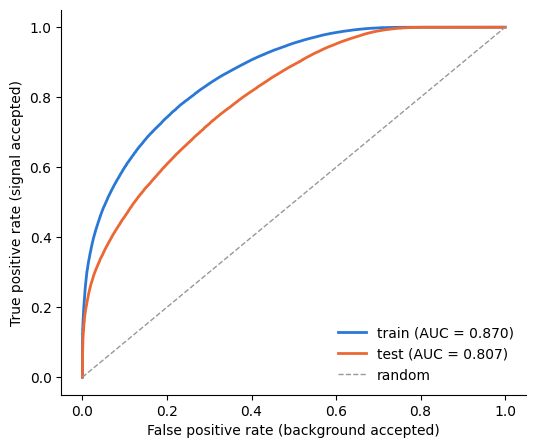

In [ ]:
# Plot AUC between predicted and true labels
y_train = torch.cat([torch.ones(len(sig_data_train)), torch.zeros(len(bkg_data_train))])
y_test = torch.cat([torch.ones(len(sig_data_test)), torch.zeros(len(bkg_data_test))])

plot_roc_curve(y_test, y_train, pred_test, pred_train)

The performance is not great yet. As we can see, there is a noticeable difference between the train and test AUC, which means the classifier is
overfitting. Can you further increase the test AUC with this simple MLP approach?

### Exercise 4 - Improving the representation

We can treat each amplitude as a set of terms and reordering the terms does not change the expression, so the classifier output should be permutation invariant. An MLP does not have this symmetry built-in and has to learn it from the training data. A transformer without positional encodings is permutation invariant by construction, which makes it a more natural fit. Let's just see how it performs; you will hear more about transformers in the next lecture

In [ ]:
class TermTransformer(nn.Module):
    def __init__(self, term_dim, d_model, n_heads, n_layers, dropout):
        """
        Transformer over the terms of an expression.

        Args:
            term_dim (int): Number of features per term.
            d_model (int): Embedding dimension of each term.
            n_heads (int): Number of attention heads.
            n_layers (int): Number of transformer layers.
            dropout (float): Dropout rate inside the transformer layers.
        """
        super().__init__()
        self.term_dim = term_dim
        self.embed = nn.Linear(term_dim, d_model)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=4 * d_model,
            dropout=dropout, batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        # (batch, max_terms * term_dim) -> (batch, max_terms, term_dim), one token per term
        x = x.view(x.shape[0], -1, self.term_dim)

        # Zero-padded rows are not real terms, the transformer should ignore them
        padding = (x.abs().sum(-1) == 0)

        h = self.transformer(self.embed(x), src_key_padding_mask=padding)

        # Average over the real terms and map to a single logit
        keep = (~padding).unsqueeze(-1).float()
        h = (h * keep).sum(1) / keep.sum(1)
        return self.head(h)

class TransformerClassifier(Classifier):
    def init_network(self):
        """
        Initializes a transformer + final linear layer.
        """
        self.net = TermTransformer(
            term_dim=self.params["term_dim"],
            d_model=self.params["d_model"],
            n_heads=self.params["n_heads"],
            n_layers=self.params["n_layers"],
            dropout=self.params.get("dropout", 0.1))

In [ ]:
transformer_params = {"term_dim": transform.term_dim,
                      "d_model": 128,
                      "n_heads": 2,
                      "n_layers": 2,
                      "dropout": 0.1,
                      "lr": 1.e-3,
                      "n_epochs": 20,
                      "batch_size": 1024,
                      "batch_size_sample": 2000}

transformer = TransformerClassifier(dims_in=transform.dims_in, params=transformer_params).to(device)
print(f"Parameters: {sum(p.numel() for p in transformer.parameters()):,}")

transformer.train_classifier(
    sig_data=sig_data_train,
    bkg_data=bkg_data_train
)

Parameters: 398,593
Training classifier for 20 epochs with lr 0.001
Epoch 0: Avg train loss = 1.3921, Avg val loss = 1.3841 time = 10.1s
Epoch 4: Avg train loss = 1.1556, Avg val loss = 1.1664 time = 50.1s
Epoch 8: Avg train loss = 1.0623, Avg val loss = 1.0665 time = 91.4s
Epoch 12: Avg train loss = 0.9806, Avg val loss = 0.9714 time = 131.7s
Epoch 16: Avg train loss = 0.9013, Avg val loss = 0.8835 time = 172.4s
Training finished in 202.9 seconds.


In [ ]:
transformer_pred_train = transformer.evaluate(
    data=torch.cat([sig_data_train, bkg_data_train])
)
transformer_pred_test = transformer.evaluate(
    data=torch.cat([sig_data_test, bkg_data_test])
)

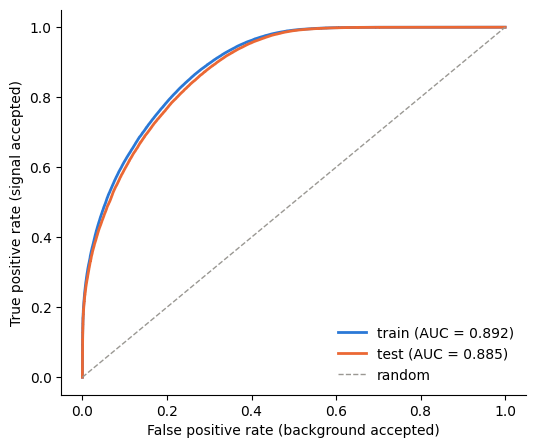

In [ ]:
plot_roc_curve(y_test, y_train, transformer_pred_test, transformer_pred_train)

### Exercise 5 - Physics data


So far, train and test data were produced by scrambling simple expressions into complicated ones using a set of elementary moves. We would now
like to test the classifier on data generated from true scattering amplitudes, some of which reduce to zero and some of which do not. These
expressions were not produced by our scrambling moves, so they test whether the classifier has learned something about the physics rather than
just the scrambling procedure.

In [ ]:
!wget -q -O data.zip "https://www.dropbox.com/scl/fo/k0k8mirgbevhqcmfg743e/APwakPDABKLys6tY2tMzcQc?rlkey=94rh100x2uoe99nslgvxrnx19&st=tkoslp49&e=1&dl=1"
!unzip -o -q data.zip -d data 2>/dev/null; ls data

ampls_test_set.pkl  background.pkl  README.md  signal.pkl


In [ ]:
amplitudes = np.load("data/ampls_test_set.pkl", allow_pickle=True)

In [ ]:
for key in amplitudes.keys():
    print(key)

id
family
description
helicities
references
label
numerator_terms
mass_dimension
max_power
expression
info


In [ ]:
t0 = time.time()

amplitudes_data = transform(amplitudes["expression"])
print(f"Amplitudes {tuple(amplitudes_data.shape)}, encoded in {round(time.time() - t0, 1)}s")

Amplitudes (136, 280), encoded in 0.1s


In [ ]:
amplitudes_labels = torch.tensor(amplitudes["label"])

In [ ]:
amplitudes_pred = transformer.evaluate(
    amplitudes_data.to(device)
)

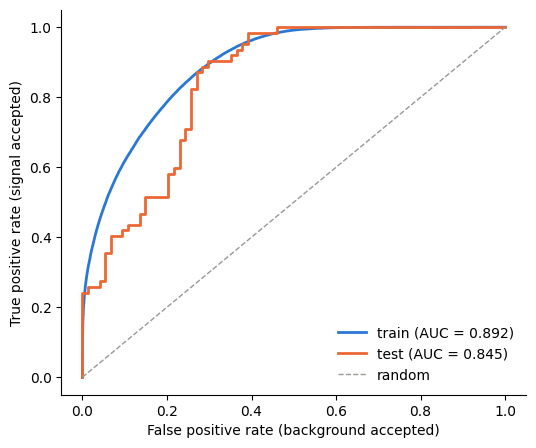

In [ ]:
plot_roc_curve(amplitudes_labels, y_train, amplitudes_pred, transformer_pred_train)